In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import Perceptron, LogisticRegression, SGDClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, PowerTransformer

# estudo árvores
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

from sklearn.metrics import ConfusionMatrixDisplay

from src.config import DADOS_LIMPOS
from src.graficos import plot_comparar_metricas_modelos
from src.models import RANDOM_STATE
from src.models import (
    grid_search_cv_classificador,
    treinar_e_validar_modelo_classificacao,
    organiza_resultados,
)

sns.set_theme(palette="bright")

In [33]:
df = pd.read_parquet(DADOS_LIMPOS)

df.head()

,area_mean,area_se,area_worst,compactness_mean,compactness_se,compactness_worst,concave points_mean,concave points_se,concave points_worst,concavity_mean,...,radius_worst,smoothness_mean,smoothness_se,smoothness_worst,symmetry_mean,symmetry_se,symmetry_worst,texture_mean,texture_se,texture_worst
0,1001.0,153.40,2019.0,0.27760,0.04904,0.6656,0.14710,0.01587,0.2654,0.3001,...,25.38,0.11840,0.006399,0.1622,0.2419,0.03003,0.4601,10.38,0.9053,17.33
1,1326.0,74.08,1956.0,0.07864,0.01308,0.1866,0.07017,0.01340,0.1860,0.0869,...,24.99,0.08474,0.005225,0.1238,0.1812,0.01389,0.2750,17.77,0.7339,23.41
2,1203.0,94.03,1709.0,0.15990,0.04006,0.4245,0.12790,0.02058,0.2430,0.1974,...,23.57,0.10960,0.006150,0.1444,0.2069,0.02250,0.3613,21.25,0.7869,25.53
3,386.1,27.23,567.7,0.28390,0.07458,0.8663,0.10520,0.01867,0.2575,0.2414,...,14.91,0.14250,0.009110,0.2098,0.2597,0.05963,0.6638,20.38,1.1560,26.50
4,1297.0,94.44,1575.0,0.13280,0.02461,0.2050,0.10430,0.01885,0.1625,0.1980,...,22.54,0.10030,0.011490,0.1374,0.1809,0.01756,0.2364,14.34,0.7813,16.67


In [34]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

In [35]:
le = LabelEncoder()

y = le.fit_transform(y)

y[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0])

In [36]:
seletor_mi = SelectKBest(mutual_info_classif, k=15)

X_mi = seletor_mi.fit_transform(X, y)

X_mi.shape

(569, 15)

In [37]:
seletor_mi.get_feature_names_out()

array(['area_mean', 'area_se', 'area_worst', 'compactness_mean',
       'compactness_worst', 'concave points_mean', 'concave points_worst',
       'concavity_mean', 'concavity_worst', 'perimeter_mean',
       'perimeter_se', 'perimeter_worst', 'radius_mean', 'radius_se',
       'radius_worst'], dtype=object)

In [38]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [39]:
preprocessamento = Pipeline(
    steps=[
        ("scaler", PowerTransformer()),
        ("selector", SelectKBest(mutual_info_classif, k=15))
    ]
)

preprocessamento_arvore = Pipeline(
    steps=[
        ("selector", SelectKBest(mutual_info_classif, k=15))
    ]
)

In [40]:
classificadores = {
    "DummyClassifier": {
        "preprocessor": None,
        "classificador": DummyClassifier(strategy="stratified")
    },
    "Perceptron": {
        "preprocessor": preprocessamento,
        "classificador": Perceptron()
    },
    "LogisticRegression": {
        "preprocessor": preprocessamento,
        "classificador": LogisticRegression()
    },
    "SGDClassifier": {
        "preprocessor": preprocessamento,
        "classificador": SGDClassifier()
    },
    
    # adicionar modelos baseados em árvores de decisão

    "DecisionTreeClassifier": {
        "preprocessor": preprocessamento_arvore,
        "classificador": DecisionTreeClassifier()
    },

    "RandomForestClassifier()": {
        "preprocessor": preprocessamento_arvore,
        "classificador": RandomForestClassifier(random_state=RANDOM_STATE)
    },
}

In [41]:
resultados = {
    nome_modelo: treinar_e_validar_modelo_classificacao(X, y, kf, **classificador)
    for nome_modelo, classificador in classificadores.items()
}

df_resultados = organiza_resultados(resultados)

df_resultados

,model,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1,test_precision,test_recall,test_roc_auc,test_average_precision,time_seconds
0,DummyClassifier,0.001176,0.013175,0.535088,0.498362,0.361446,0.375,0.348837,0.482149,0.36938,0.014351
1,DummyClassifier,0.001066,0.009454,0.596491,0.552244,0.410256,0.457143,0.372093,0.498362,0.376428,0.01052
2,DummyClassifier,0.000569,0.005033,0.552632,0.526786,0.413793,0.4,0.428571,0.578373,0.414466,0.005601
3,DummyClassifier,0.000668,0.003924,0.491228,0.473214,0.369565,0.34,0.404762,0.448413,0.348872,0.004592
4,DummyClassifier,0.000515,0.00399,0.566372,0.528504,0.395062,0.410256,0.380952,0.473843,0.360725,0.004505
5,Perceptron,0.070379,0.008028,0.938596,0.918605,0.911392,1.0,0.837209,0.987881,0.982831,0.078406
6,Perceptron,0.063356,0.005439,0.894737,0.865051,0.842105,0.969697,0.744186,0.985915,0.977328,0.068795
7,Perceptron,0.070905,0.006526,0.921053,0.922619,0.896552,0.866667,0.928571,0.982143,0.978283,0.07743
8,Perceptron,0.084161,0.005644,0.95614,0.960317,0.942529,0.911111,0.97619,0.995701,0.993515,0.089805
9,Perceptron,0.056999,0.007006,0.964602,0.952381,0.95,1.0,0.904762,0.996982,0.995172,0.064005


In [42]:
df_resultados.groupby("model").mean().sort_values("test_recall")

,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1,test_precision,test_recall,test_roc_auc,test_average_precision,time_seconds
model,,,,,,,,,,
DummyClassifier,0.000799,0.007115,0.548362,0.515822,0.390024,0.39648,0.387043,0.496228,0.373974,0.007914
DecisionTreeClassifier,0.047531,0.006637,0.908663,0.902319,0.876568,0.880621,0.877409,0.902319,0.817162,0.054168
SGDClassifier,0.119321,0.010585,0.931486,0.920645,0.905256,0.939535,0.877519,0.985296,0.980839,0.129906
Perceptron,0.06916,0.006528,0.935026,0.923795,0.908516,0.949495,0.878184,0.989724,0.985426,0.075688
RandomForestClassifier(),0.126348,0.009584,0.942028,0.934762,0.919985,0.939632,0.905869,0.98843,0.983118,0.135932
LogisticRegression,0.075905,0.008708,0.952585,0.947818,0.935613,0.944606,0.929125,0.992078,0.989293,0.084613


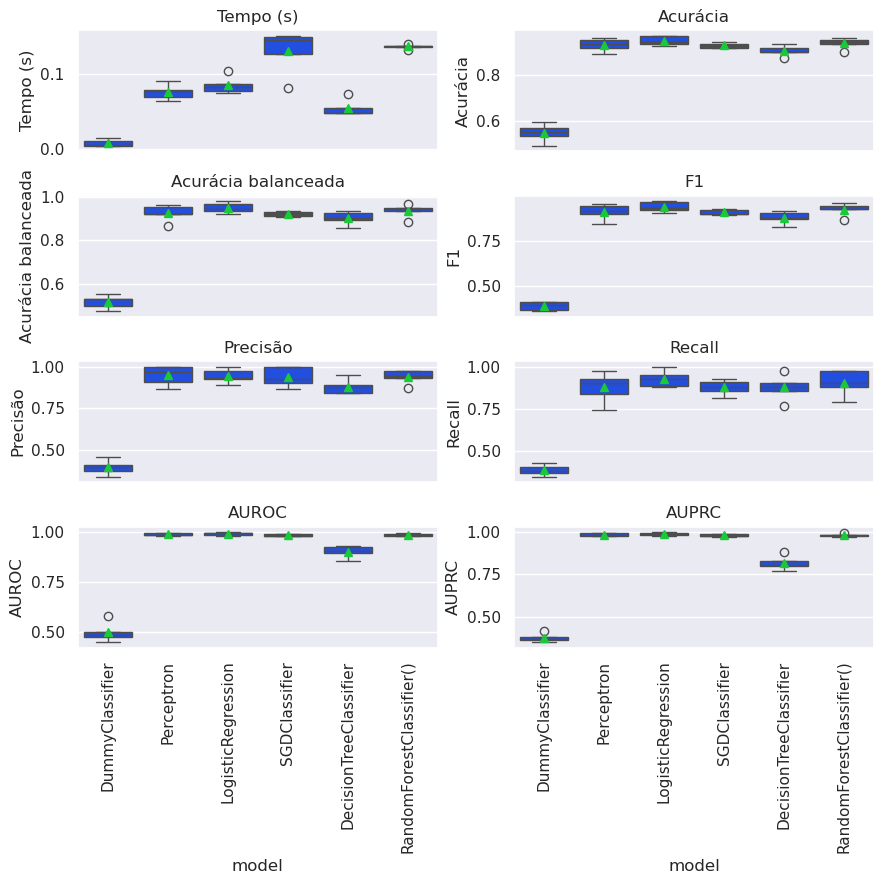

In [43]:
plot_comparar_metricas_modelos(df_resultados)

Hiperparâmetros usualmente utilizados para otimizar DecisionTreeClassifier:

- **`max_depth`**: Limita a profundidade da árvore, prevenindo overfitting.
- **`min_samples_split`**: Número mínimo de amostras para dividir um nó.
- **`min_samples_leaf`**: Mínimo de amostras em um nó folha.
- **`max_features`**: Número de features a serem consideradas na divisão.
- **`criterion`**: Função para medir a qualidade da divisão.
- **`splitter`**: Estratégia de divisão dos nós.
- **`class_weight`**: Ponderação das classes para lidar com desbalanceamento.
- **`ccp_alpha`**: Controla a poda de custo-complexidade. Maior valor resulta em mais poda.


**Pré-poda (pre-pruning)** e **pós-poda (post-pruning)** são técnicas usadas para controlar a complexidade de uma árvore de decisão e evitar o overfitting:

- **Pré-poda**: A árvore para de crescer antes que todas as folhas sejam puras. Limites são impostos durante o crescimento, como definir um `max_depth`, `min_samples_split`, ou `min_samples_leaf`. Evita a criação de nós desnecessários desde o início.

- **Pós-poda**: A árvore é completamente construída e, em seguida, ramos irrelevantes ou muito específicos são removidos. O hiperparâmetro `ccp_alpha` (poda de custo-complexidade) é um exemplo de pós-poda.

O **custo-complexidade** é uma técnica de poda que busca equilibrar a complexidade da árvore de decisão com a qualidade da predição. O objetivo é encontrar um ponto ótimo onde a árvore seja suficientemente complexa para explicar os dados, mas não tão complexa a ponto de overfitting. 

A fórmula de custo-complexidade combina o erro de predição da árvore com um termo de penalização proporcional ao número de nós terminais. Ou seja, ela minimiza o erro de predição e o número de nós simultaneamente. Isso é controlado pelo hiperparâmetro **`ccp_alpha`**.

- Quando `ccp_alpha` é 0, não há poda.
- Quando `ccp_alpha` aumenta, nós são podados se a redução no erro de predição não justificar o aumento na complexidade.

Hiperparâmetros usualmente utilizados para otimizar RandomForestClassifier:

- **`n_estimators`**: Número de árvores na floresta.
- **`max_depth`**: Limita a profundidade da árvore, prevenindo overfitting.
- **`min_samples_split`**: Número mínimo de amostras para dividir um nó.
- **`min_samples_leaf`**: Mínimo de amostras em um nó folha.
- **`max_features`**: Número de features a serem consideradas na divisão.
- **`criterion`**: Função para medir a qualidade da divisão.
- **`splitter`**: Estratégia de divisão dos nós.
- **`class_weight`**: Ponderação das classes para lidar com desbalanceamento.


In [45]:
# param grid para o DecisionTreeClassifier
param_grid_DTC = {
    "clf__max_depth": [3, 5, 10, None],  # Limita a profundidade da árvore
    "clf__min_samples_split": [2, 5, 10],  # Mínimo de amostras para dividir um nó
    "clf__min_samples_leaf": [1, 2, 5],  # Mínimo de amostras em um nó folha
    "clf__max_features": [None, "sqrt", "log2"],  # Features para divisão
    "clf__criterion": ["gini", "entropy"],  # Critério para divisão
    "clf__splitter": ["best", "random"],  # Estratégia de divisão dos nós
    "clf__class_weight": [None, "balanced"],  # Ponderação das classes
    "clf__ccp_alpha": [0.0, 0.01, 0.1]  # Controla a poda
}

In [46]:
# param grid para o RandomForest
param_grid_RDF = {
    "clf__n_estimators": [10, 50, 100], #numero de arvores
    "clf__max_depth": [3, 5, 10, None],  # Limita a profundidade da árvore
    "clf__min_samples_split": [2, 5, 10],  # Mínimo de amostras para dividir um nó
    "clf__min_samples_leaf": [1, 2, 5],  # Mínimo de amostras em um nó folha
    "clf__max_features": [None, "sqrt", "log2"],  # Features para divisão
    "clf__criterion": ["gini", "entropy"],  # Critério para divisão
    "clf__class_weight": [None, "balanced"],  # Ponderação das classes
}

In [47]:
# classificador baseado em árvore de decisão
clf = DecisionTreeClassifier(random_state=RANDOM_STATE)

grid_searchDTC = grid_search_cv_classificador(
    clf, param_grid_DTC, kf, preprocessamento_arvore, refit_metric="recall"
)

grid_searchDTC

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        Pipeline(steps=[('selector',
                                                         SelectKBest(k=15,
                                                                     score_func=<function mutual_info_classif at 0x70b1f69d1120>))])),
                                       ('clf',
                                        DecisionTreeClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'clf__ccp_alpha': [0.0, 0.01, 0.1],
                         'clf__class_weight': [None, 'balanced'],
                         'clf__criterion': ['gini', 'entropy'],
                         'clf__max_depth': [3, 5, 10, None],
                         'clf__max_features': [None, 'sqrt', 'log2'],
                         'clf__min_samples_leaf': [1, 2, 5],
                         'clf__min_samples_split': [2, 5, 10],
                         'clf__splitter': ['best', 'random']},
             refit='recall',
             scoring=['accuracy', 'balanced_accuracy', 'f1', 'precision',
                      'recall', 'roc_auc', 'average_precision'],
             verbose=1)

In [ ]:
# classificador baseado em árvore de decisão
clf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-3)

grid_searchRDF = grid_search_cv_classificador(
    clf, param_grid_RDF, kf, preprocessamento_arvore, refit_metric="recall"
)

grid_searchRDF

In [ ]:
grid_searchDTC.fit(X, y)

In [ ]:
grid_searchDTC.best_params_

In [ ]:
grid_searchDTC.best_score_

In [ ]:
grid_searchDTC.best_estimator_

In [ ]:
grid_searchDTC.best_estimator_["preprocessor"].get_feature_names_out()

In [ ]:
plt.figure(figsize=(15, 8))

plot_tree(
    grid_searchDTC.best_estimator_["clf"],
    filled=True,
    feature_names=grid_searchDTC.best_estimator_["preprocessor"].get_feature_names_out(),
    fontsize=8
)

plt.show()

In [ ]:
grid_searchDTC.best_estimator_["clf"].get_depth()

In [ ]:
pd.Series(
    grid_searchDTC.best_estimator_["clf"].feature_importances_,
    index = grid_searchDTC.best_estimator_["preprocessor"].get_feature_names_out(),
).sort_values(ascending=False)

In [ ]:
pd.Series(
    grid_searchDTC.best_estimator_["clf"].feature_importances_,
    index = grid_searchDTC.best_estimator_["preprocessor"].get_feature_names_out(),
).sort_values(ascending=True).plot.barh();

In [ ]:
perm_imp = permutation_importance(
    grid_searchDTC.best_estimator_,
    X,
    y,
    n_repeats=10,
    random_state=RANDOM_STATE
)

In [ ]:
fig, ax = plt.subplots()

ordem = perm_imp.importances_mean.argsort()

ax.boxplot(
    perm_imp.importances[ordem].T, 
    vert=False,
    tick_labels=X.columns[ordem]       
)

ax.axvline(x=0, linestyle="--")
ax.set_xlabel("Decréscimo da acurácia")
ax.grid(True, linestyle=":")

plt.show()

In [ ]:
ConfusionMatrixDisplay.from_estimator(
    grid_searchDTC.best_estimator_,
    X,
    y,
    display_labels=le.classes_,
    normalize="true"
)

plt.grid(False)

plt.show()